# Tutorial 04b

This tutorial uses observations from Birmingham car parks to solve a binary classification problem: is at least 80% of a car park's capacity occupied?

The previous tutorial predicted a continuous count and compared network architectures; this tutorial predicts a class and performs a four-stage hyperparameter search. At each stage, one group of settings is varied and the configuration with the highest validation F1 for the busy class is carried forward. The test set is evaluated only once, after all four stages are complete.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `parking_birmingham.csv`.
- **On your own computer.** Open this file from the `04 Artificial neural networks` folder, so `parking_birmingham.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "04 Artificial neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/04 Artificial neural networks


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, scikit-learn scales the columns and scores the predictions, and PyTorch builds the network.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn torch torchinfo


Note: you may need to restart the kernel to use updated packages.


## A busy car park

`parking_birmingham.csv` is the Parking Birmingham data of Stolfi (2017), UCI Machine Learning Repository, https://doi.org/10.24432/C51K5Z. The counts come from car parks operated by NCP for Birmingham City Council and are shared under the UK Open Government Licence.

Each row represents one car park at one time in autumn 2016. A row is labelled **busy** when occupancy divided by capacity is at least 0.8. Approximately one observation in six belongs to the busy class.

The inputs are the hour, the weekday (Monday is 0), the capacity, and which car park it is. Occupancy is used only to build the busy label. `StandardScaler` is fit on the training rows only.


## What the rows look like

The next cell prints the first rows, then how full the car parks are. The dashed line on the histogram is 0.8. Rows on or above that line are busy. The bar on the right counts the two groups.


rows 35717
columns ['SystemCodeNumber', 'Capacity', 'Occupancy', 'LastUpdated']
  SystemCodeNumber  Capacity  Occupancy          LastUpdated
0      BHMBCCMKT01       577         61  2016-10-04 07:59:42
1      BHMBCCMKT01       577         64  2016-10-04 08:25:42
2      BHMBCCMKT01       577         80  2016-10-04 08:59:42
3      BHMBCCMKT01       577        107  2016-10-04 09:32:46
4      BHMBCCMKT01       577        150  2016-10-04 09:59:48
car parks 30
       Capacity  Occupancy      rate
count  35717.00   35717.00  35717.00
mean    1397.55     642.23      0.49
std     1179.33     656.96      0.27
min      220.00      -8.00     -0.02
25%      500.00     210.00      0.26
50%      849.00     446.00      0.47
75%     2009.00     798.00      0.72
max     4675.00    4327.00      1.04
busy
not busy    29643
busy         6074


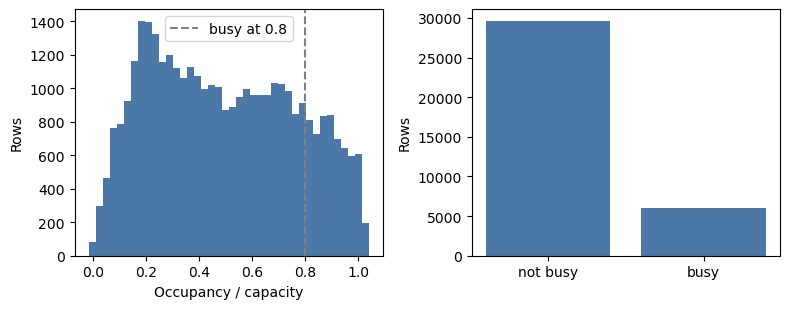

In [4]:
park = pd.read_csv("parking_birmingham.csv")
print("rows", len(park))
print("columns", list(park.columns))
print(park.head().to_string())
print("car parks", park["SystemCodeNumber"].nunique())

park["time"] = pd.to_datetime(park["LastUpdated"])
park["hour"] = park["time"].dt.hour
park["rate"] = park["Occupancy"] / park["Capacity"]
park["busy"] = (park["rate"] >= 0.8).astype(int)
print(park[["Capacity", "Occupancy", "rate"]].describe().round(2).to_string())
print(park["busy"].value_counts().rename({0: "not busy", 1: "busy"}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(park["rate"], bins=40, color="#4C78A8")
axes[0].axvline(0.8, color="gray", linestyle="--", label="busy at 0.8")
axes[0].set_xlabel("Occupancy / capacity")
axes[0].set_ylabel("Rows")
axes[0].legend()
counts = park["busy"].value_counts().sort_index()
axes[1].bar(["not busy", "busy"], [int(counts.get(0, 0)), int(counts.get(1, 0))], color="#4C78A8")
axes[1].set_ylabel("Rows")
fig.tight_layout()
plt.show()


Most observations lie below the dashed threshold, and the busy class contains only about one sixth of the rows. We therefore focus on F1 for the minority busy class: a model that predicts every row as quiet could achieve high accuracy while failing completely to detect busy car parks.


## Training days, validation days, test days

The records are sorted by time. There are 73 dates, from 4 October 2016 through 19 December 2016. The first 36 dates, through 10 November, are the training set. The next 18 dates, 11 November through 28 November, are the validation set. The last 19 dates, 29 November through 19 December, are the test set.

Every car park observed on one date stays in the same set. If 29 November is a test day, every car park that morning and that afternoon is a test row.

Car park `BHMBRTARC01` is recorded only from 13 to 18 December, inside the test set. It has no column of its own. On those rows every car-park column is 0, and the network sees the hour, the weekday, and the capacity.

The label is an integer: 0 when the car park is quiet, and 1 when it is busy.

`shuffle=True` in the training loader only mixes training rows into batches. A later date stays in the validation set or the test set.


In [5]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

park = pd.read_csv("parking_birmingham.csv")
park["time"] = pd.to_datetime(park["LastUpdated"])
park["day"] = park["time"].dt.normalize()
park["hour"] = park["time"].dt.hour
park["weekday"] = park["time"].dt.weekday
park["busy"] = (park["Occupancy"] / park["Capacity"] >= 0.8).astype(int)
park = park.sort_values(["time", "SystemCodeNumber"]).reset_index(drop=True)
days = park["day"].drop_duplicates().tolist()
n_days = len(days)
train_days = days[: int(n_days * 0.50)]
valid_days = days[int(n_days * 0.50) : int(n_days * 0.75)]
test_days = days[int(n_days * 0.75) :]
train = park[park["day"].isin(train_days)].copy()
valid = park[park["day"].isin(valid_days)].copy()
test = park[park["day"].isin(test_days)].copy()
print("training days", train_days[0].date(), "to", train_days[-1].date(), len(train_days))
print("validation days", valid_days[0].date(), "to", valid_days[-1].date(), len(valid_days))
print("test days", test_days[0].date(), "to", test_days[-1].date(), len(test_days))

num = ["hour", "weekday", "Capacity"]
cat = ["SystemCodeNumber"]
X_train_np = pd.concat([train[num].astype(float), pd.get_dummies(train[cat], dtype=int)], axis=1)
X_valid_np = pd.concat([valid[num].astype(float), pd.get_dummies(valid[cat], dtype=int)], axis=1)
X_test_np = pd.concat([test[num].astype(float), pd.get_dummies(test[cat], dtype=int)], axis=1)
X_valid_np = X_valid_np.reindex(columns=X_train_np.columns, fill_value=0)
X_test_np = X_test_np.reindex(columns=X_train_np.columns, fill_value=0)

scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train_np).astype("float32")
X_valid_np = scaler.transform(X_valid_np).astype("float32")
X_test_np = scaler.transform(X_test_np).astype("float32")
y_train_np = train["busy"].to_numpy()
y_valid_np = valid["busy"].to_numpy()
y_test_np = test["busy"].to_numpy()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train = torch.tensor(X_train_np, dtype=torch.float32).to(device)
X_valid = torch.tensor(X_valid_np, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test_np, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train_np, dtype=torch.long).to(device)
y_valid = torch.tensor(y_valid_np, dtype=torch.long).to(device)
y_test = torch.tensor(y_test_np, dtype=torch.long).to(device)

print("rows", len(train), len(valid), len(test))
print("input columns", X_train_np.shape[1])
print("share busy, train", round(float(y_train_np.mean()), 2))


training days 2016-10-04 to 2016-11-10 36
validation days 2016-11-11 to 2016-11-28 18
test days 2016-11-29 to 2016-12-19 19
rows 17496 8964 9257
input columns 32
share busy, train 0.14


## Two scores, then a class

The output layer has two units, one score for each class. `nn.CrossEntropyLoss` compares these scores with the observed class labels, and the larger score determines the predicted class. For the ROC curve, the second softmax probability is used as the model's score for the busy class.

The hidden-layer activation is an argument of the class, so the same shape can hold a sigmoid, a tanh, or a ReLU. This first summary uses ReLU and 8 hidden units. It shows where the weights sit before the sizes change.


In [6]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchinfo import summary

class Simple_Network(nn.Module):
    def __init__(self, inp_dim, hid_dim, out_dim, activation):
        super().__init__()
        self.input_layer = nn.Linear(inp_dim, hid_dim)
        self.activation_function = activation
        self.output_layer = nn.Linear(hid_dim, out_dim)

    def forward(self, x):
        h = self.activation_function(self.input_layer(x))
        return self.output_layer(h)

class Two_Layer(nn.Module):
    def __init__(self, inp_dim, hid1, hid2, out_dim, activation):
        super().__init__()
        self.fc1 = nn.Linear(inp_dim, hid1)
        self.fc2 = nn.Linear(hid1, hid2)
        self.fc3 = nn.Linear(hid2, out_dim)
        self.activation_function = activation

    def forward(self, x):
        h = self.activation_function(self.fc1(x))
        h = self.activation_function(self.fc2(h))
        return self.fc3(h)

model = Simple_Network(X_train.shape[1], 8, 2, nn.ReLU()).to(device)
print(summary(model, input_size=(1, X_train.shape[1]), verbose=0))


Layer (type:depth-idx)                   Output Shape              Param #
Simple_Network                           [1, 2]                    --
├─Linear: 1-1                            [1, 8]                    264
├─ReLU: 1-2                              [1, 8]                    --
├─Linear: 1-3                            [1, 2]                    18
Total params: 282
Trainable params: 282
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00


## Step 1. Change the shape

A wider layer can combine the hour and the car park in more ways. A second layer mixes those combinations again. For this step the other settings stay fixed: ReLU, Adam, learning rate 0.001, weight penalty 0, 40 epochs, and batches of 512. The seed is reset before each fit. `shuffle=True` only changes the order of the training rows inside each epoch. Rows from the validation dates and the test dates stay where they are.

`8` is one hidden layer of 8 units. `32` is the same network, only wider. `16-8` is two hidden layers, 16 units then 8. The printed score is the validation F1 of busy. The highest of the three is the shape used in Step 2, Step 3, and Step 4.


In [8]:
from sklearn.metrics import f1_score

loss_fn = nn.CrossEntropyLoss()
for name in ["8", "32", "16-8"]:
    torch.manual_seed(0)
    generator = torch.Generator()
    generator.manual_seed(0)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=512, shuffle=True, generator=generator)
    if name == "8":
        model = Simple_Network(X_train.shape[1], 8, 2, nn.ReLU()).to(device)
    elif name == "32":
        model = Simple_Network(X_train.shape[1], 32, 2, nn.ReLU()).to(device)
    else:
        model = Two_Layer(X_train.shape[1], 16, 8, 2, nn.ReLU()).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    for epoch in range(40):
        model.train()
        for Xb, yb in loader:
            loss = loss_fn(model(Xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(X_valid).argmax(dim=1).cpu().numpy()
    print(name, "validation F1", f"{f1_score(y_valid_np, pred):.3f}")


8 validation F1 0.617
32 validation F1 0.700
16-8 validation F1 0.713


Eight hidden units reach a validation F1 of about 0.617. Thirty-two units reach about 0.700. Sixteen units followed by eight reach about 0.713.

These scores are on 11 November through 28 November. The highest is 16 units then 8, so Step 2, Step 3, and Step 4 all use that shape. They still use ReLU, learning rate 0.001, and weight penalty 0, until a later step changes one of those three.


## Step 2. On that shape, change the activation

The shape is now fixed at 16 units then 8. The learning rate stays at 0.001, and the weight penalty stays at 0. Only the hidden-layer activation changes. The highest of these three is the activation used in Step 3 and Step 4.

`nn.Sigmoid` squeezes a weighted sum into a number between 0 and 1. `nn.Tanh` squeezes it into a number between −1 and 1. `nn.ReLU` passes a positive sum through and replaces a negative sum with 0.


In [9]:
for name, activation in [("sigmoid", nn.Sigmoid()), ("tanh", nn.Tanh()), ("relu", nn.ReLU())]:
    torch.manual_seed(0)
    generator = torch.Generator()
    generator.manual_seed(0)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=512, shuffle=True, generator=generator)
    model = Two_Layer(X_train.shape[1], 16, 8, 2, activation).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    for epoch in range(40):
        model.train()
        for Xb, yb in loader:
            loss = loss_fn(model(Xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(X_valid).argmax(dim=1).cpu().numpy()
    print(name, "validation F1", f"{f1_score(y_valid_np, pred):.3f}")


sigmoid validation F1 0.633
tanh validation F1 0.676
relu validation F1 0.713


Sigmoid reaches a validation F1 of about 0.633. Tanh reaches about 0.676. ReLU reaches about 0.713. The ReLU score matches Step 1, because this fit repeats the winner of that step. ReLU is the highest, so Step 3 keeps ReLU.


## Step 3. On that activation, change the learning rate

The shape stays at 16 then 8, and the activation stays ReLU. The weight penalty stays at 0. The learning rate is the size of the step Adam takes after each batch. The three values below are 0.001, 0.01, and 0.05. The highest is the learning rate used in Step 4.


In [10]:
for step in [0.001, 0.01, 0.05]:
    torch.manual_seed(0)
    generator = torch.Generator()
    generator.manual_seed(0)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=512, shuffle=True, generator=generator)
    model = Two_Layer(X_train.shape[1], 16, 8, 2, nn.ReLU()).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=step)
    for epoch in range(40):
        model.train()
        for Xb, yb in loader:
            loss = loss_fn(model(Xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(X_valid).argmax(dim=1).cpu().numpy()
    print("learning rate", step, "validation F1", f"{f1_score(y_valid_np, pred):.3f}")


learning rate 0.001 validation F1 0.713
learning rate 0.01 validation F1 0.747
learning rate 0.05 validation F1 0.707


A step of 0.001 reaches about 0.713. This is the ReLU fit from Step 2, trained again. A step of 0.01 reaches about 0.747. A step of 0.05 reaches about 0.707, below the step of 0.001. The highest is 0.01, so Step 4 uses learning rate 0.01.


## Step 4. On that learning rate, change the weight penalty

`weight_decay` pulls each weight toward zero on every update. The shape, the activation, and the learning rate stay at the winners already chosen: 16 then 8, ReLU, and learning rate 0.01. Only the penalty changes. The penalty with the highest validation F1 is the one taken to the test days.


In [11]:
for penalty in [0.0, 0.001, 0.01]:
    torch.manual_seed(0)
    generator = torch.Generator()
    generator.manual_seed(0)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=512, shuffle=True, generator=generator)
    model = Two_Layer(X_train.shape[1], 16, 8, 2, nn.ReLU()).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=penalty)
    for epoch in range(40):
        model.train()
        for Xb, yb in loader:
            loss = loss_fn(model(Xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(X_valid).argmax(dim=1).cpu().numpy()
    print("weight_decay", penalty, "validation F1", f"{f1_score(y_valid_np, pred):.3f}")


weight_decay 0.0 validation F1 0.747
weight_decay 0.001 validation F1 0.738
weight_decay 0.01 validation F1 0.673


A penalty of 0 reaches about 0.747. This repeats the learning-rate 0.01 fit from Step 3. A penalty of 0.001 reaches about 0.738, and 0.01 reaches about 0.673. The highest is a penalty of 0, so the test days are scored with `weight_decay` 0.


## Score the test days

The four steps kept one network: 16 units then 8, ReLU, learning rate 0.01, and `weight_decay` 0. The cell trains that network once more, draws the training loss and the validation loss, and then scores the test rows once.

A row is called busy when its probability of busy is at least 0.5. Precision is the share of those called-busy rows that really are busy. Recall is the share of busy rows that this rule finds. F1 combines the two. The confusion matrix is the four counts behind them.

The ROC moves that 0.5 cut. The horizontal axis is the share of quiet rows called busy. The vertical axis is recall. AUC is the area under that curve. The dashed line is a score that ranks rows at random.


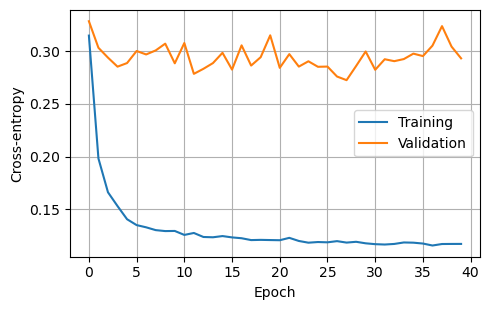

precision 0.908
recall 0.647
F1 0.755
AUC 0.946


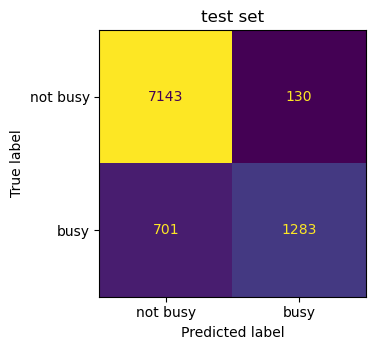

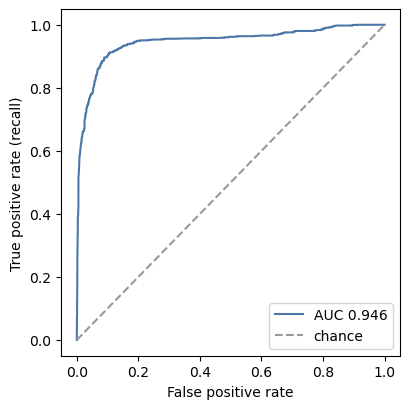

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(0)
generator = torch.Generator()
generator.manual_seed(0)
loader = DataLoader(TensorDataset(X_train, y_train), batch_size=512, shuffle=True, generator=generator)
model = Two_Layer(X_train.shape[1], 16, 8, 2, nn.ReLU()).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
train_loss, val_loss = [], []
for epoch in range(40):
    model.train()
    total = 0.0
    for Xb, yb in loader:
        loss = loss_fn(model(Xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    train_loss.append(total / len(loader.dataset))
    model.eval()
    with torch.no_grad():
        val_loss.append(loss_fn(model(X_valid), y_valid).item())

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(train_loss, label="Training")
ax.plot(val_loss, label="Validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

model.eval()
with torch.no_grad():
    probability = torch.softmax(model(X_test), dim=1)[:, 1].cpu().numpy()
pred = (probability >= 0.5).astype(int)
print("precision", f"{precision_score(y_test_np, pred):.3f}")
print("recall", f"{recall_score(y_test_np, pred):.3f}")
print("F1", f"{f1_score(y_test_np, pred):.3f}")
print("AUC", f"{roc_auc_score(y_test_np, probability):.3f}")

fig, ax = plt.subplots(figsize=(4.2, 3.6))
cm = confusion_matrix(y_test_np, pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["not busy", "busy"]).plot(ax=ax, colorbar=False)
ax.set_title("test set")
fig.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test_np, probability)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot(fpr, tpr, color="#4C78A8", label=f"AUC {roc_auc_score(y_test_np, probability):.3f}")
ax.plot([0, 1], [0, 1], color="0.6", linestyle="--", label="chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend()
fig.tight_layout()
plt.show()


On the test days, 29 November through 19 December, the busy class has precision about 0.908, recall about 0.647, F1 about 0.755, and AUC about 0.946. Precision is the share of rows called busy that really are busy. Recall is the share of busy rows this rule finds, about two thirds here.


## A question

Each stage compares three choices and retains one. The four groups of candidates are:

- shapes: `8`, `32`, `16-8`
- activations: sigmoid, tanh, ReLU
- learning rates: 0.001, 0.01, 0.05
- weight penalties: 0, 0.001, 0.01

Could we train every combination of these four lists, instead of changing one list at a time? How many networks do the four steps fit, and how many networks would every combination take? On this table, is the full list a large job?


## An answer

The four steps fit 3 + 3 + 3 + 3 = 12 networks. Three of those fits repeat a winner the previous step already trained: ReLU in Step 2 repeats the shape chosen in Step 1, learning rate 0.001 in Step 3 repeats that ReLU, and a penalty of 0 in Step 4 repeats learning rate 0.01.

Every combination of the same four lists is 3 × 3 × 3 × 3 = 81 networks. That is 81 / 12 = 6.75 times the one-at-a-time search. Each fit is 40 epochs on about 17,500 training rows, so 81 fits is a long run on a laptop. The full list also grows quickly. One extra learning rate would add 3 × 3 × 3 = 27 fits to the full list, and 1 fit to the one-at-a-time search.

The full list would train combinations this path skips. Learning rate 0.05 lost in Step 3, so it is never paired with sigmoid, with tanh, or with the shapes `8` and `32`. A strong combination can sit off the path and never be trained.

The cell that scores the test days trains the kept network once more, so the notebook fits 13 networks in all. That extra fit draws the loss curves and scores the later dates. A search over all 81 combinations would still finish by training its own winner once for the same figures.
